# REWIND batch results: what did the pipeline find?

Reads what `pipeline.ipynb` saved in `outputs/batch/` and shows it. Run `pipeline.ipynb` first, then *Run All* here. It never re-runs the
pipeline, so it is quick and safe to re-run. Pictures are small to keep this file small; commit it **without outputs**.

1. Overview per dataset · 2. Per video · 3. Gates compared · 4. MEVA: all cameras on one clock ·
5. One video in detail (timeline, keyframes, **labelled moments that got no keyframe**, events, **its captions**) ·
6. Captions across all videos (speed, unparsed answers, unusual events, the hand check) · 7. Run times ·
8. **Search** (needs `search.ipynb`): recall against the ground truth, baselines, examples, speed

In [1]:
import json
from pathlib import Path

import cv2
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display

import caption_eval as ce
import captions as cap
import search as se
import visualize as viz
from video_utils import format_hms

import os
OUT_ROOT = Path(os.environ.get("REWIND_OUT_ROOT", "outputs/batch"))
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
pd.set_option("display.precision", 2)


def show_fig(fig):
    display(Image(viz.fig_png_bytes(fig)))
    plt.close(fig)


def show_img(img, quality=65):
    display(Image(viz.jpeg_bytes(img, quality)))


def vdir(r):
    return OUT_ROOT / r["dataset"] / r["video_id"]


def read_csv(p):
    return pd.read_csv(p) if Path(p).exists() else None


S = pd.read_csv(OUT_ROOT / "batch_summary.csv")
sel = pd.read_csv(OUT_ROOT / "selection_used.csv", keep_default_na=False)
ok = S[S.get("status_cpu", "").astype(str) == "ok"].copy() if "status_cpu" in S else S.iloc[0:0]
ok["minutes"] = ok.duration_s / 60
has = lambda col: col in ok and ok[col].notna().any()   # noqa: E731  (a phase may not have run yet)
print(f"{len(S)} videos in the batch, {len(ok)} with stage 1-2 results"
      + (f", {int(ok.status_gpu.astype(str).eq('ok').sum())} with GPU results" if "status_gpu" in ok else ", no GPU phase")
      + (f", {int(ok.vlm_clips.fillna(0).gt(0).sum())} with clip captions" if has("vlm_clips") else ", no captions yet"))

38 videos in the batch, 38 with stage 1-2 results, 38 with GPU results, 38 with clip captions


## 1. Overview per dataset
- **active %**: share of the video the gate kept (time-weighted). Low = lots of empty footage skipped.
- **reduction**: how many fewer frames than "1 frame per second" go to the expensive models.
- **GT items with a keyframe**: share of labelled moments (MEVA activities / UCA sentences) with at least one keyframe
  inside. A moment without one can never be found by search. Compared with **uniform sampling** of the same number of
  frames: if gating isn't better than that, it isn't helping.
- **video min per CPU min**: speed of stages 1-2 (higher = faster than real time).

In [2]:
def overview(d):
    g = d.groupby("dataset")
    t = pd.DataFrame({
        "videos": g.size(), "hours": g.duration_s.sum() / 3600,
        "active %": g.apply(lambda x: (x.active_pct * x.duration_s).sum() / x.duration_s.sum()),
        "segments": g.segments.sum(), "keyframes": g.keyframes.sum(),
        "keyframes / min": g.apply(lambda x: x.keyframes.sum() / x.minutes.sum()),
        "reduction (x)": g.apply(lambda x: x.naive_frames.sum() / max(1, x.keyframes.sum())),
        "video min per CPU min": g.apply(lambda x: x.duration_s.sum() / max(1e-9, x.cpu_s.sum())),
    })
    w = d.dropna(subset=["gt_kf_hit"]) if "gt_kf_hit" in d else d.iloc[0:0]
    if len(w):
        gw = w.groupby("dataset")
        t["videos with GT"] = gw.size()
        t["GT items"] = gw.gt_items.sum()
        t["GT items with a keyframe %"] = gw.apply(lambda x: 100 * (x.gt_kf_hit * x.gt_items).sum() / x.gt_items.sum())
        t["uniform, same count %"] = gw.apply(lambda x: 100 * (x.gt_kf_hit_uniform * x.gt_items).sum() / x.gt_items.sum())
        t["GT events a segment covers %"] = gw.apply(lambda x: 100 * (x.gt_event_recall * x.gt_items).sum() / x.gt_items.sum())
    if "gpu_s" in d and d.gpu_s.notna().any():
        t["video min per GPU min"] = g.apply(lambda x: x.duration_s.sum() / max(1e-9, x.gpu_s.fillna(0).sum()))
        t["index records"] = g.index_records.sum()
        if "embedding_dim" in d:
            t["videos with SigLIP embeddings"] = g.apply(lambda x: int((x.embedding_dim.fillna(0) > 0).sum()))
    if "vlm_clips" in d and d.vlm_clips.notna().any():
        t["clip captions"] = g.vlm_clips.sum()
        t["frame captions"] = g.vlm_frames.sum()
    return t

display(overview(ok).round(2))
# sanity check: does the real video length match the length the file name / annotation promised?
chk = ok.merge(sel[["dataset", "video_id", "duration_s"]].rename(columns={"duration_s": "expected_s"}), on=["dataset", "video_id"])
bad = chk[(chk.duration_s - chk.expected_s.astype(float)).abs() > 5]
print(f"videos whose real length differs from the expected length by > 5 s: {len(bad)}")
if len(bad):
    display(bad[["dataset", "video_id", "expected_s", "duration_s"]])
err = S[S[[c for c in S.columns if c.startswith("status_")]].astype(str).apply(lambda r: r.str.startswith("error").any(), axis=1)]
if len(err):
    display(Markdown(f"**{len(err)} video(s) failed** (traceback in `error_*.json` in their folder)"))
    display(err[["dataset", "video_id"] + [c for c in err.columns if c.startswith("status_")]])

,videos,hours,active %,segments,keyframes,keyframes / min,reduction (x),video min per CPU min,videos with GT,GT items,GT items with a keyframe %,"uniform, same count %",GT events a segment covers %,video min per GPU min,index records,videos with SigLIP embeddings,clip captions,frame captions
dataset,,,,,,,,,,,,,,,,,,
meva,12,1.0,42.68,58,302,5.03,11.92,13.63,12,680,48.82,49.56,63.82,12.15,1631,12,64,220
uca,26,1.0,65.91,97,735,12.19,4.90,22.46,26,194,80.93,93.81,75.77,16.69,1042,26,103,0


videos whose real length differs from the expected length by > 5 s: 0


## 2. Per video
Left: how much of each video the gate kept. Right: labelled moments with a keyframe, gated keyframes vs the same
number of frames spread evenly (points above the diagonal = gating helps).

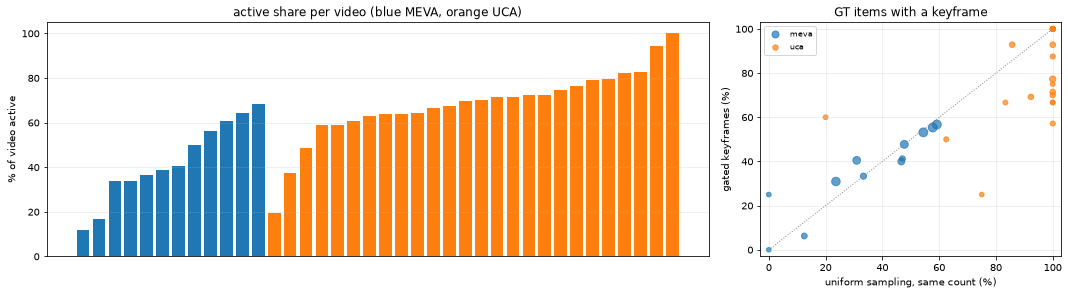

,dataset,video_id,category,minutes,active_pct,segments,keyframes,reduction_x,gt_items,gt_kf_hit,gt_kf_hit_uniform,gt_event_recall
0,meva,2018-03-13.15-50-00.15-55-00.school.G328.r13,school,5.00,60.92,8,24,12.50,42,0.40,0.31,0.60
1,meva,2018-03-13.15-50-00.15-55-00.school.G421.r13,school,5.00,64.20,8,75,4.00,168,0.55,0.58,0.75
2,meva,2018-03-13.15-50-02.15-55-02.school.G424.r13,school,5.00,56.29,8,29,10.34,30,0.40,0.47,0.60
3,meva,2018-03-13.15-50-03.15-55-03.school.G336.r13,school,5.00,68.29,5,17,17.65,21,0.33,0.33,0.81
4,meva,2018-03-13.15-55-00.16-00-00.school.G328.r13,school,5.00,33.80,5,12,25.00,3,0.00,0.00,0.00
5,meva,2018-03-13.15-55-00.16-00-00.school.G421.r13,school,5.00,49.93,5,57,5.26,201,0.57,0.59,0.65
6,meva,2018-03-13.15-55-02.16-00-02.school.G424.r13,school,5.00,16.92,4,7,42.86,16,0.06,0.12,0.00
7,meva,2018-03-13.15-55-03.16-00-03.school.G336.r13,school,5.00,38.71,3,28,10.71,79,0.53,0.54,0.51
8,meva,2018-03-13.16-05-00.16-10-00.school.G328.r13,school,5.00,33.93,3,11,27.27,17,0.41,0.47,0.65
9,meva,2018-03-13.16-05-00.16-10-00.school.G421.r13,school,5.00,11.73,1,6,50.00,4,0.25,0.00,1.00


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.2), gridspec_kw={"width_ratios": [2.2, 1]})
d = ok.sort_values(["dataset", "active_pct"])
colors = d.dataset.map({"meva": "C0", "uca": "C1"}).fillna("C2")
axes[0].bar(range(len(d)), d.active_pct, color=colors)
axes[0].set(ylabel="% of video active", xticks=[], title="active share per video (blue MEVA, orange UCA)")
axes[0].grid(alpha=.25, axis="y")
if "gt_kf_hit" in d:
    w = d.dropna(subset=["gt_kf_hit"])
    for ds_, c in (("meva", "C0"), ("uca", "C1")):
        x = w[w.dataset == ds_]
        axes[1].scatter(100 * x.gt_kf_hit_uniform, 100 * x.gt_kf_hit, s=18 + x.gt_items.clip(upper=60), color=c, alpha=.7, label=ds_)
    axes[1].plot([0, 100], [0, 100], color="#888", ls=":", lw=1)
    axes[1].set(xlabel="uniform sampling, same count (%)", ylabel="gated keyframes (%)", xlim=(-3, 103), ylim=(-3, 103),
                title="GT items with a keyframe")
    axes[1].legend(fontsize=8); axes[1].grid(alpha=.25)
fig.tight_layout()
show_fig(fig)
cols = ["dataset", "video_id", "category", "minutes", "active_pct", "segments", "keyframes", "reduction_x",
        "gt_items", "gt_kf_hit", "gt_kf_hit_uniform", "gt_event_recall"]
display(ok[[c for c in cols if c in ok]].sort_values(["dataset", "video_id"]).reset_index(drop=True))

### UCA by category
UCF-Crime videos are partly not CCTV (news / YouTube compilations with cuts, replays, several angles). A cut looks like
the whole frame moving, so such videos come out mostly "active". This table shows which categories suffer.

In [4]:
u = ok[ok.dataset == "uca"]
if len(u):
    display(u.groupby("category").agg(videos=("video_id", "size"), minutes=("minutes", "sum"),
                                      active_pct=("active_pct", "mean"), keyframes_per_min=("keyframes", "sum"),
                                      gt_kf_hit=("gt_kf_hit", "mean"), gt_kf_hit_uniform=("gt_kf_hit_uniform", "mean"))
            .assign(keyframes_per_min=lambda t: t.keyframes_per_min / t.minutes).round(2))
else:
    print("no UCA videos")

,videos,minutes,active_pct,keyframes_per_min,gt_kf_hit,gt_kf_hit_uniform
category,,,,,,
Abuse,2,3.47,65.84,11.82,0.69,0.92
Arson,2,4.43,73.64,17.39,0.83,1.00
Assault,2,3.79,45.51,13.98,0.62,0.88
Burglary,2,1.96,86.83,7.65,0.55,0.41
Explosion,2,1.69,86.24,19.53,1.00,1.00
Fighting,2,4.15,71.65,14.95,0.85,1.00
Normal_Videos,2,2.13,67.68,12.65,0.88,1.00
RoadAccidents,2,6.54,65.11,10.70,0.94,1.00
Robbery,2,3.03,59.15,11.90,0.83,1.00


## 3. Gates compared
The batch computes segments and keyframes for every gate (only the chosen one, `gate` in the config, saves JPGs and
feeds stages 3-4). Ground-truth numbers per gate are in each video's `gt_eval_gates.csv` / `gt_eval_keyframes.csv`.

In [5]:
gates = [c[len("active_pct_"):] for c in ok.columns if c.startswith("active_pct_")]
rows = []
for _, r in ok.iterrows():
    gk = read_csv(vdir(r) / "gt_eval_keyframes.csv")
    gg = read_csv(vdir(r) / "gt_eval_gates.csv")
    for m in gates:
        row = {"dataset": r.dataset, "gate": m, "minutes": r.minutes, "active_pct": r[f"active_pct_{m}"],
               "keyframes": r[f"keyframes_{m}"], "gt_items": r.get("gt_items", 0) or 0}
        if gk is not None:
            gk_ = gk.set_index(gk.columns[0])
            row["kf_hit"] = gk_.loc[f"keyframes_{m}", "gt_events_with_keyframe"] if f"keyframes_{m}" in gk_.index else np.nan
        if gg is not None:
            gg_ = gg.set_index(gg.columns[0])
            row["event_recall"] = gg_.loc[m, "event_recall"] if m in gg_.index else np.nan
        rows.append(row)
G = pd.DataFrame(rows)
if len(G):
    def wavg(x, col, w):
        x = x.dropna(subset=[col]) if col in x else x.iloc[0:0]
        return (x[col] * x[w]).sum() / x[w].sum() if len(x) and x[w].sum() else np.nan
    t = G.groupby(["dataset", "gate"]).apply(lambda x: pd.Series({
        "active %": wavg(x, "active_pct", "minutes"), "keyframes": x.keyframes.sum(),
        "GT items with a keyframe %": 100 * wavg(x, "kf_hit", "gt_items"),
        "GT events a segment covers %": 100 * wavg(x, "event_recall", "gt_items")}))
    display(t.round(1))

active %  keyframes  GT items with a keyframe %  GT events a segment covers %
dataset gate                                                                                
meva    diff       44.3      313.0                        51.0                          69.3
        fused      43.0      296.0                        51.2                          67.6
        mog2       42.7      302.0                        48.8                          63.8
uca     diff       74.0      864.0                        88.1                          83.5
        fused      75.0      818.0                        85.6                          86.1
        mog2       65.9      735.0                        80.9                          75.8

## 4. MEVA: all cameras on one clock
Each row is a camera; x = real time of day. Orange = motion segments, black ticks = keyframes, green bars = labelled
activities (only for clips that have annotations). Same moment, several angles: this is the multi-camera view the
final system needs.

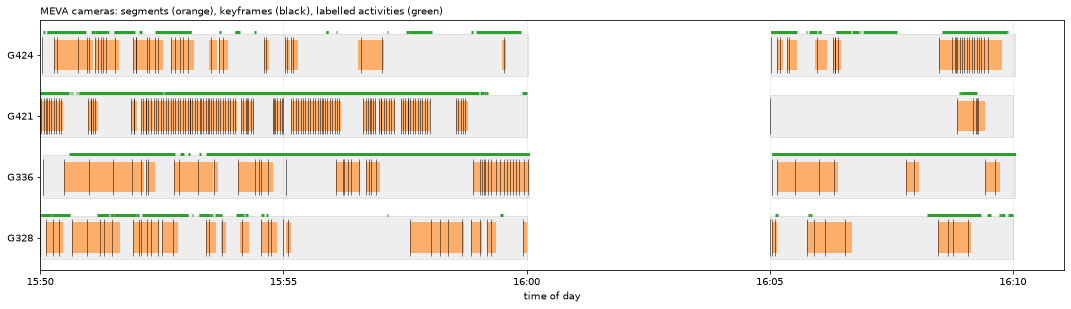

,n,with_keyframe,mean_len_s
label,,,
person_talks_to_person,149,0.86,40.42
person_exits_scene_through_structure,69,0.58,2.61
person_picks_up_object,69,0.10,0.62
person_texts_on_phone,63,0.71,14.84
person_puts_down_object,46,0.20,0.62
person_transfers_object,45,0.36,2.65
hand_interacts_with_person,43,0.37,5.41
person_opens_facility_door,37,0.43,2.46
vehicle_turns_left,24,0.21,3.63


In [6]:
m = ok[ok.dataset == "meva"].copy()
if len(m) and m.start_wallclock.astype(str).str.len().gt(0).any():
    m["t0"] = pd.to_datetime(m.start_wallclock)
    cams = sorted(m.camera_id.astype(str).unique())
    fig, ax = plt.subplots(figsize=(15, 0.8 * len(cams) + 1.2))
    for _, r in m.iterrows():
        y = cams.index(str(r.camera_id))
        t0 = r.t0
        def tt(sec):
            return matplotlib.dates.date2num(t0 + pd.to_timedelta(sec, unit="s"))
        ax.barh(y, tt(r.duration_s) - tt(0), left=tt(0), height=0.7, color="#eee", edgecolor="#ccc", lw=0.5)
        segs = read_csv(vdir(r) / "segments.csv")
        if segs is not None:
            for s in segs.itertuples():
                ax.barh(y, tt(s.end_s) - tt(s.start_s), left=tt(s.start_s), height=0.5, color="#fdae6b")
        kf = read_csv(vdir(r) / "keyframes.csv")
        if kf is not None and len(kf):
            ax.vlines([tt(x) for x in kf.timestamp_s], y - 0.3, y + 0.3, color="k", lw=0.5)
        gt = read_csv(vdir(r) / "gt.csv")
        if gt is not None:
            for g in gt.itertuples():
                ax.plot([tt(g.start_s), tt(g.end_s)], [y + 0.38, y + 0.38], color="#2ca02c", lw=3, solid_capstyle="butt")
    ax.set_yticks(range(len(cams)), cams)
    ax.xaxis_date(); ax.xaxis.set_major_formatter(matplotlib.dates.DateFormatter("%H:%M"))
    ax.set_xlabel("time of day"); ax.grid(alpha=.25, axis="x")
    ax.set_title("MEVA cameras: segments (orange), keyframes (black), labelled activities (green)", loc="left", fontsize=10)
    fig.tight_layout()
    show_fig(fig)
    # which activities are labelled, and how many got a keyframe
    acts = []
    for _, r in m.iterrows():
        gt = read_csv(vdir(r) / "gt.csv")
        if gt is not None and len(gt):
            acts.append(gt.assign(camera=r.camera_id))
    if acts:
        A = pd.concat(acts, ignore_index=True).assign(len_s=lambda a: a.end_s - a.start_s)
        display(A.groupby("label").agg(n=("label", "size"), with_keyframe=("has_keyframe", "mean"),
                                       mean_len_s=("len_s", "mean"))
                .sort_values("n", ascending=False).round(2))
    else:
        print("none of the selected MEVA clips has an activity annotation (see pipeline.ipynb, section 1)")
else:
    print("no MEVA videos with a wall-clock start")

## 5. One video in detail
Set `VIDEO_ID` (a `video_id` from the tables above). `None` = the MEVA clip with the most labelled activities,
else the first video.

**meva / 2018-03-13.15-55-00.16-00-00.school.G421.r13**: 5.0 min, 1920x1072, 30.0 fps, gate mog2: 5 segments, 49.9% active, 57 keyframes (5x fewer than 1 fps), 201 labelled items, 57% with a keyframe

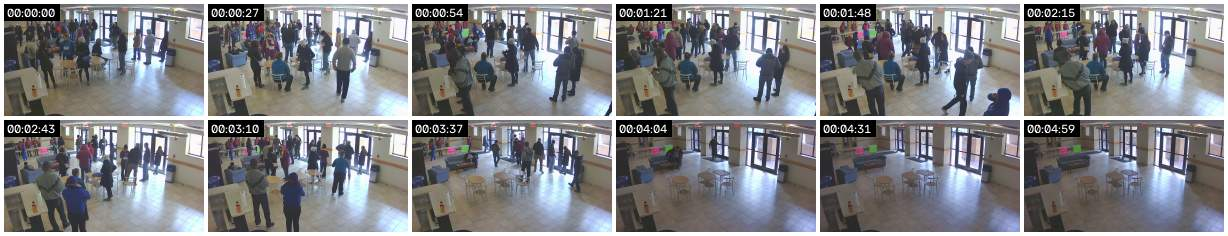

In [7]:
VIDEO_ID = None
THUMB_W = 150

if VIDEO_ID is None:
    c = ok.sort_values("gt_items", ascending=False) if "gt_items" in ok else ok
    VIDEO_ID = (c[c.dataset == "meva"] if (c.dataset == "meva").any() else c).video_id.iloc[0]
R = ok[ok.video_id == VIDEO_ID].iloc[0]
D_ = vdir(R)
VIDEO = Path(R.path)
scores = pd.read_csv(D_ / "motion_scores.csv")
segments = pd.read_csv(D_ / "segments.csv")
kf = pd.read_csv(D_ / "keyframes.csv")
gt = read_csv(D_ / "gt.csv")
display(Markdown(f"**{R.dataset} / {VIDEO_ID}**: {R.minutes:.1f} min, {R.resolution}, {R.fps:.1f} fps, "
                 f"gate {R.gate}: {int(R.segments)} segments, {R.active_pct:.1f}% active, {int(R.keyframes)} keyframes "
                 f"({R.reduction_x:.0f}x fewer than 1 fps)" +
                 (f", {int(R.gt_items)} labelled items, {100 * R.gt_kf_hit:.0f}% with a keyframe" if gt is not None else "")))
show_img(viz.contact_sheet(VIDEO, R.fps, np.linspace(0, max(0, R.duration_s - 1), 12), cols=6, width=200))

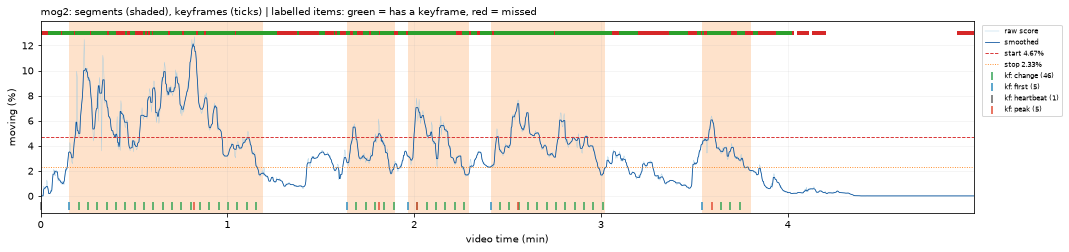

,segment_id,start_hms,end_hms,duration_s,peak_score
0,0,00:00:09.200,00:01:11.600,62.4,0.13
1,1,00:01:38.400,00:01:54.000,15.6,0.06
2,2,00:01:58.000,00:02:17.600,19.6,0.08
3,3,00:02:24.600,00:03:01.200,36.6,0.08
4,4,00:03:32.600,00:03:48.200,15.6,0.06


In [8]:
col = f"score_{R.gate}"
scale = 1 if R.gate == "fused" else 100
fig, ax = plt.subplots(figsize=(15, 3.6))
viz.plot_timeline(ax, scores, col, segments, R.threshold_start, R.threshold_stop,
                  max(1, round(1.0 * 5)), kf, f"{R.gate}: segments (shaded), keyframes (ticks)", scale=scale,
                  ylabel="ratio to threshold" if scale == 1 else "moving (%)")
if gt is not None:
    top = ax.get_ylim()[1]
    for g in gt.itertuples():
        ax.plot([g.start_s / 60, g.end_s / 60], [0.93 * top] * 2, lw=4, solid_capstyle="butt",
                color="#2ca02c" if g.has_keyframe else "#d62728")
    ax.set_title(ax.get_title(loc="left") + " | labelled items: green = has a keyframe, red = missed", loc="left", fontsize=10)
ax.legend(loc="upper left", bbox_to_anchor=(1.005, 1), fontsize=7)
fig.tight_layout()
show_fig(fig)
display(segments[["segment_id", "start_hms", "end_hms", "duration_s", "peak_score"]].head(30))

### What triggered the strongest segments
6 frames spread over each segment, and the peak frame with the MOG2 mask on top (**red** = moving pixels that count,
**yellow** = blobs the lighting filter removed). The mask is recomputed from the previous 60 s, so it is close to,
not identical with, what the full pass saw.

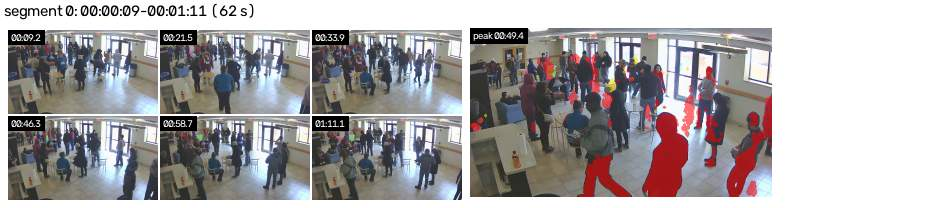

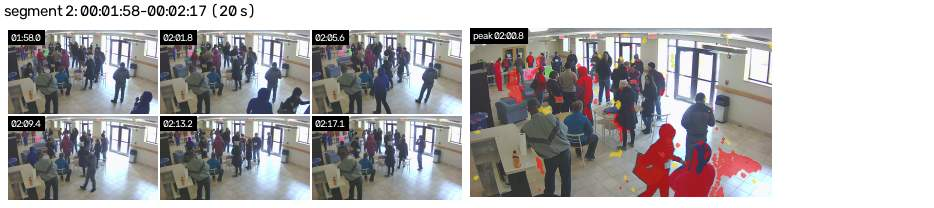

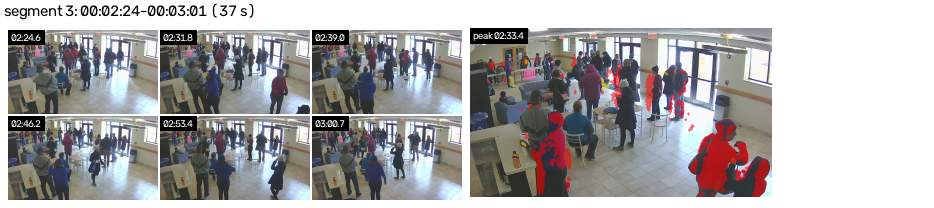

In [9]:
TOP_N = 3
cfg_path = OUT_ROOT / "batch_config.json"
scan_params = json.loads(cfg_path.read_text())["scan"] if cfg_path.exists() else None
if scan_params is None:
    import motion_gating as mg
    scan_params = mg.SCAN_PARAMS
import motion_gating as mg
for s in segments.nlargest(TOP_N, "peak_score").itertuples():
    idx = [int(round(t * R.fps)) for t in np.linspace(s.start_s, max(s.start_s, s.end_s - 0.5), 6)]
    fr = viz.frames_at(VIDEO, idx)
    strip = viz.grid([viz.label(viz.thumb(fr[i], THUMB_W), format_hms(i / R.fps)[3:10], scale=0.35) for i in idx if i in fr],
                     cols=3, pad=2)
    peak, mask, removed = mg.foreground_mask_at(VIDEO, int(s.peak_frame_idx), scan_params, "mog2")
    ov = viz.label(viz.thumb(viz.overlay_mask(peak, mask, removed=removed), 2 * THUMB_W + 2),
                   f"peak {format_hms(s.peak_time_s)[3:10]}", scale=0.35)
    row = viz.grid([strip, ov], cols=2, pad=6)
    show_img(np.vstack([viz.header(f"segment {s.segment_id}: {s.start_hms[:8]}-{s.end_hms[:8]} ({s.duration_s:.0f} s)",
                                   row.shape[1]), row]))

### All keyframes
Timestamp and segment on top, reason at the bottom (blue first · red peak · green change · purple maxgap · grey heartbeat).

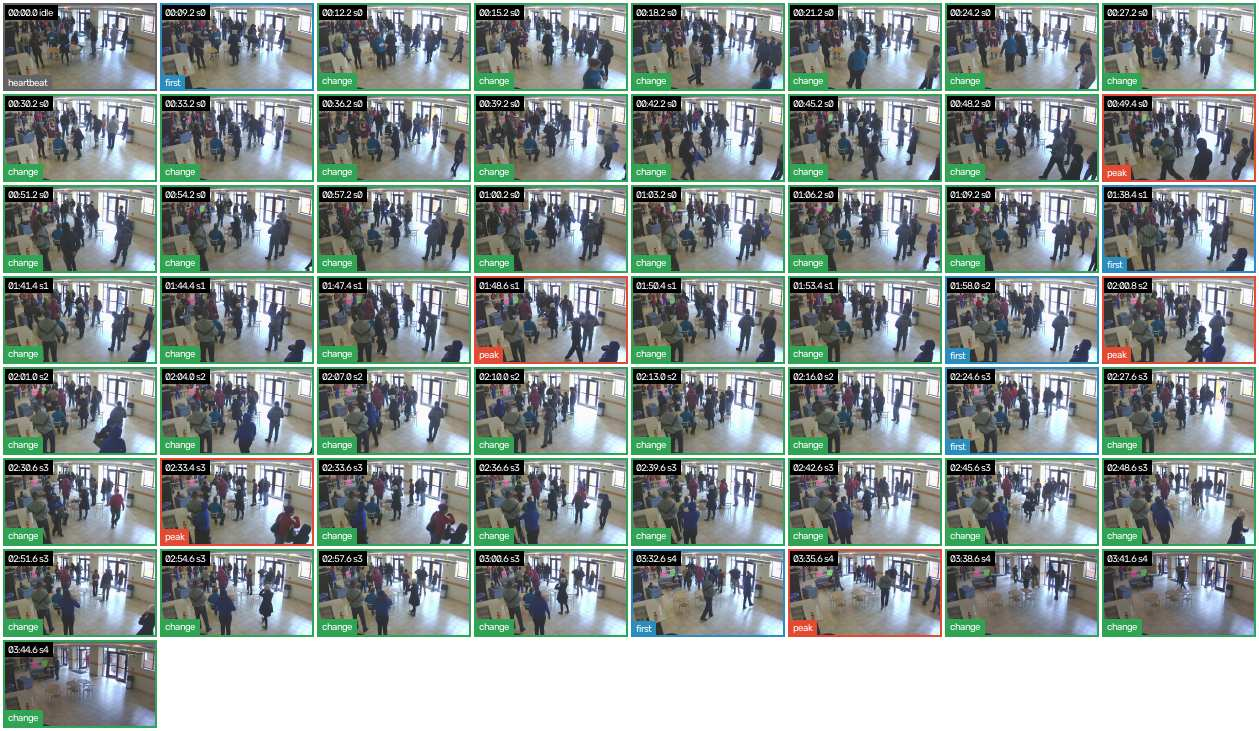

In [10]:
tiles = []
for r in kf.itertuples():
    img = cv2.imread(str(D_ / "keyframes" / r.filename))
    if img is None:
        continue
    c = viz.hex_to_bgr(viz.REASON_COLORS.get(r.reason, "#000000"))
    t = viz.label(viz.thumb(img, THUMB_W), f"{r.timestamp_hms[3:10]} " + ("idle" if r.segment_id < 0 else f"s{r.segment_id}"), scale=0.33)
    tiles.append(viz.border(viz.label(t, r.reason, pos="bottom", scale=0.33, bg=c), c, 2))
show_img(viz.grid(tiles[:96], cols=8, pad=3), quality=55) if tiles else print("no keyframe JPGs")
if len(tiles) > 96:
    print(f"showing 96 of {len(tiles)}")

### Labelled moments that got no keyframe
These are the failures that matter: the search can never return them. One frame from the middle of each, with its
label. Use them as failure examples in the report (and check whether the label is even visible).

**Per gate** (UCA: frame precision/recall mean little, its sentences cover the whole video)

,frame_precision,frame_recall,frame_f1,event_recall,active_pct
Unnamed: 0,,,,,
diff,1.0,0.61,0.76,0.70,51.87
mog2,1.0,0.59,0.74,0.65,49.93
fused,1.0,0.58,0.73,0.68,49.47


**Labelled items with at least one keyframe, per frame set**

,keyframes,gt_events_with_keyframe
Unnamed: 0,,
keyframes_diff,59.0,0.58
keyframes_mog2,57.0,0.57
keyframes_fused,57.0,0.58
uniform_same_count,57.0,0.59
naive_1fps,300.0,0.93


87 of 201 labelled items have no keyframe


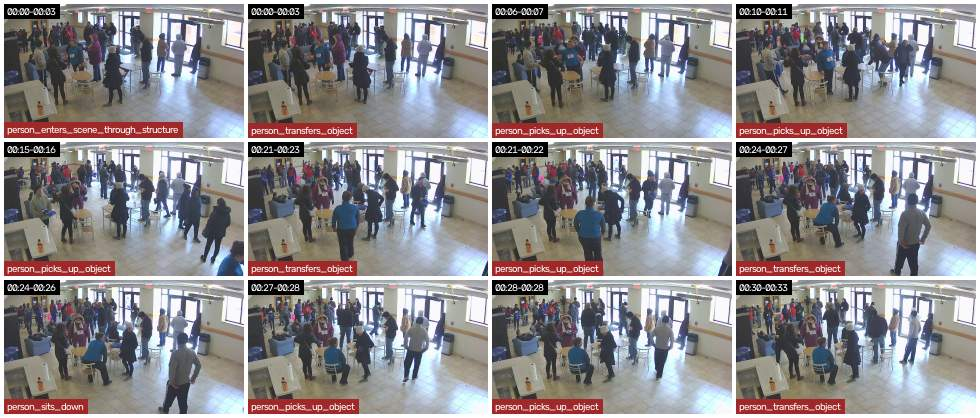

,start_s,end_s,label
8,0.60,3.07,person_enters_scene_through_structure
9,0.90,3.73,person_transfers_object
13,6.47,7.00,person_picks_up_object
16,10.60,11.07,person_picks_up_object
22,15.73,16.23,person_picks_up_object
26,21.27,23.67,person_transfers_object
27,21.53,22.07,person_picks_up_object
29,24.33,27.03,person_transfers_object
30,24.93,26.23,person_sits_down
32,27.83,28.30,person_picks_up_object


In [11]:
if gt is None:
    print("this video has no ground truth")
else:
    gk = read_csv(D_ / "gt_eval_keyframes.csv")
    gg = read_csv(D_ / "gt_eval_gates.csv")
    if gg is not None:
        display(Markdown("**Per gate** (UCA: frame precision/recall mean little, its sentences cover the whole video)"))
        display(gg.set_index(gg.columns[0]).round(3))
    if gk is not None:
        display(Markdown("**Labelled items with at least one keyframe, per frame set**"))
        display(gk.set_index(gk.columns[0]).round(3))
    miss = gt[~gt.has_keyframe.astype(bool)]
    print(f"{len(miss)} of {len(gt)} labelled items have no keyframe")
    if len(miss):
        mid = {i: int(round((g.start_s + g.end_s) / 2 * R.fps)) for i, g in miss.head(12).iterrows()}
        fr = viz.frames_at(VIDEO, mid.values())
        tiles = [viz.label(viz.label(viz.thumb(fr[f], 240), f"{format_hms(miss.at[i, 'start_s'])[3:8]}-"
                                     f"{format_hms(miss.at[i, 'end_s'])[3:8]}", scale=0.35),
                           str(miss.at[i, "label"])[:40], pos="bottom", scale=0.32, bg=(40, 40, 160))
                 for i, f in mid.items() if f in fr]
        if tiles:
            show_img(viz.grid(tiles, cols=4))
        display(miss[["start_s", "end_s", "label"]].head(20))

### Stages 3-4 (only if the GPU phase ran)

**Samplers compared** (which frames go to the captioner / index)

,keyframes,active_keyframes,keyframes_per_min,reduction_vs_naive_x,coverage_mean,coverage_p10,redundancy_mean,event_recall,track_recall
phash,72.0,71.0,14.4,4.17,0.98,0.97,0.98,0.67,0.84
novelty,10.0,9.0,2.0,30.00,0.97,0.96,0.94,0.32,0.47
kcenter,315.0,314.0,63.0,0.95,0.99,0.98,0.99,0.99,1.00
importance,53.0,52.0,10.6,5.66,0.98,0.97,0.97,0.61,0.88
v1_keyframes,57.0,56.0,11.4,5.26,0.98,0.97,0.98,0.57,0.88


**Labelled items with a keyframe, per sampler**

,keyframes,gt_events_with_keyframe
phash,72.0,0.60
novelty,10.0,0.29
kcenter,315.0,0.74
importance,53.0,0.53
v1_keyframes,57.0,0.57


**Events** (380; most common)

,count
key,
person_appears,328
fighting,14
crowd,11
handbag_appears,11
person_walking,5
door_interaction,4
person_loitering,2
object_left,2
box_appears,2


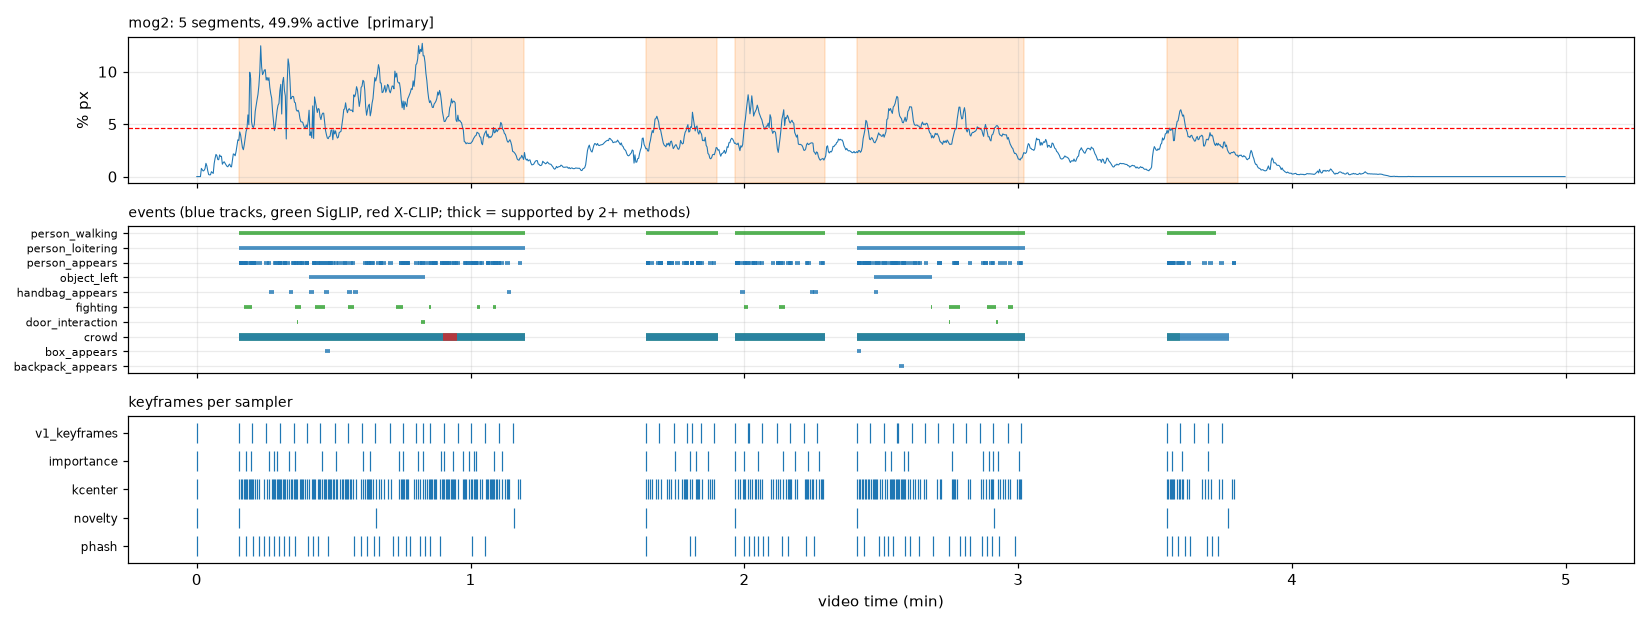

**Hand-off records** (first 5)

,camera_id,video,frame_idx,timestamp_s,segment_id,wallclock,importance,embedding_row,events,objects,siglip_tag
0,G421,2018-03-13.15-55-00.16-00-00.school.G421.r13.avi,0,0.00,-1,2018-03-13T15:55:00,0.0,0,[],{},person_walking
1,G421,2018-03-13.15-55-00.16-00-00.school.G421.r13.avi,276,9.20,0,2018-03-13T15:55:09.200000,1.0,1,"[crowd, person_appears, person_loitering, pers...",{'person': 23},person_walking
2,G421,2018-03-13.15-55-00.16-00-00.school.G421.r13.avi,292,9.73,0,2018-03-13T15:55:09.733333,1.0,2,"[crowd, person_appears, person_loitering, pers...",{'person': 23},person_walking
3,G421,2018-03-13.15-55-00.16-00-00.school.G421.r13.avi,300,10.00,0,2018-03-13T15:55:10,1.0,3,"[crowd, person_appears, person_loitering, pers...",{'person': 22},person_walking
4,G421,2018-03-13.15-55-00.16-00-00.school.G421.r13.avi,308,10.27,0,2018-03-13T15:55:10.266667,1.0,4,"[crowd, fighting, person_appears, person_loite...",{'person': 23},person_walking


In [12]:
ev_dir = D_ / "events"
if (ev_dir / "sampling_comparison.csv").exists():
    display(Markdown("**Samplers compared** (which frames go to the captioner / index)"))
    display(pd.read_csv(ev_dir / "sampling_comparison.csv", index_col=0).round(3))
    if (ev_dir / "gt_eval_sampling.csv").exists():
        display(Markdown("**Labelled items with a keyframe, per sampler**"))
        display(pd.read_csv(ev_dir / "gt_eval_sampling.csv", index_col=0).round(3))
    ev = read_csv(ev_dir / "events.csv")
    if ev is not None and len(ev):
        display(Markdown(f"**Events** ({len(ev)}; most common)"))
        display(ev.key.value_counts().head(15).to_frame("count"))
    if (ev_dir / "timeline.png").exists():
        display(Image(filename=str(ev_dir / "timeline.png"), width=1000))
    recs = ev_dir / "index_records.jsonl"
    if recs.exists():
        display(Markdown("**Hand-off records** (first 5)"))
        display(pd.read_json(recs, lines=True).head())
else:
    print("no GPU results for this video (STAGES did not include 'gpu', or it failed: see error_gpu.json)")

### Captions for this video (stage 5)
Each clip: the frames the VLM saw (offset from the clip start on each), its JSON answer, and the **labelled moments
in the same time span** (MEVA activities / UCA sentences), so you can judge the caption against the truth. Then the
first frame captions. Look for things the caption names that aren't in the frames (hallucinations) and things
clearly visible that it missed.

**6 clip captions, 0 frame captions** · model `/mnt/5T_storage/hat_detection_vlm/hf_cache/hub/models--Qwen--Qwen2.5-VL-7B-Instruct/snapshots/cc594898137f460bfe9f0759e9844b3ce807cfb5` · frames from `index` · unparsed answers: 0

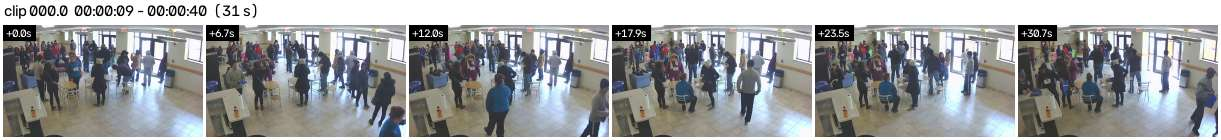

**Summary:** A person wearing a purple jacket with a number "14" on it walks towards the center of the room, while another person in a blue jacket sits down at a table. The group continues to move around the room, with some individuals standing and others sitting.  
**Actions:** person in a purple jacket with a number "14" walks towards the center of the room; person in a blue jacket sits down at a table; individuals continue to move around the room, with some standing and others sitting  
**People** (max 18 at once): person in a purple jacket with a number "14"; person in a blue jacket; individuals standing and sitting in various positions throughout the room  
**Vehicles:** — · **Objects:** table with chairs; couch; trash can; water bottle on a table  
**Labelled in this span (46):** `00:00` person_texts_on_phone; `00:00` person_texts_on_phone; `00:00` person_talks_to_person; `00:00` person_talks_to_person; `00:00` person_talks_to_person; `00:00` person_talks_to_person; `00:00` person_talks_to_person; `00:02` person_talks_to_person

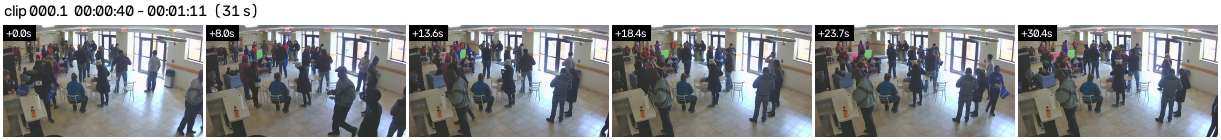

**Summary:** A person in a blue jacket walks towards the center of the room, while another individual in a gray jacket moves slightly to the right. The group remains mostly stationary, with some individuals adjusting their positions.  
**Actions:** person in a blue jacket walks towards the center of the room; individual in a gray jacket moves slightly to the right  
**People** (max 19 at once): man in a blue jacket with a backpack; woman in a gray jacket; man in a black jacket with a backpack; woman in a blue jacket; man in a gray jacket; woman in a black jacket; man in a black jacket; woman in a pink jacket; man in a red jacket; woman in a black jacket; man in a black jacket; woman in a black jacket; man in a black jacket; woman in a black jacket; man in a black jacket; woman in a black jacket; man in a black jacket; woman in a black jacket; man in a black jacket  
**Vehicles:** — · **Objects:** blue jacket; gray jacket; black jacket with a backpack; blue jacket; gray jacket; black jacket; pink jacket; red jacket; black jacket; black jacket; black jacket; black jacket; black jacket; black jacket; black jacket; black jacket; black jacket; black jacket; black jacket  
**Labelled in this span (34):** `00:00` person_talks_to_person; `00:00` person_talks_to_person; `00:00` person_talks_to_person; `00:00` person_talks_to_person; `00:22` person_texts_on_phone; `00:27` person_talks_to_person; `00:33` person_talks_to_person; `00:34` person_talks_to_person

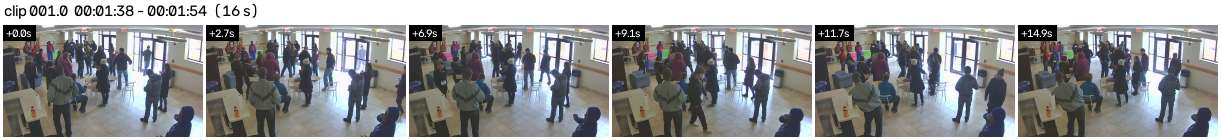

**Summary:** A person in a red jacket exits through the door, while another individual in a blue jacket moves closer to the center of the room.  
**Actions:** person in a red jacket exits through the door; individual in a blue jacket moves closer to the center of the room  
**People** (max 20 at once): man in gray jacket with a backpack; woman in black coat with white hat; man in blue jacket; person in red jacket; man in black jacket with a backpack; woman in black coat; man in gray jacket; woman in black coat; man in black jacket; woman in black coat; man in gray jacket; woman in black coat; man in gray jacket; woman in black coat; man in gray jacket; woman in black coat; man in gray jacket; woman in black coat; man in gray jacket; woman in black coat  
**Vehicles:** — · **Objects:** orange bottle on the counter; blue trash bin; green sign; white table; chairs  
**Labelled in this span (24):** `00:00` person_talks_to_person; `00:51` person_talks_to_person; `00:53` person_talks_to_person; `01:14` person_talks_to_person; `01:22` person_talks_to_person; `01:34` person_texts_on_phone; `01:36` person_exits_scene_through_structure; `01:36` person_opens_facility_door

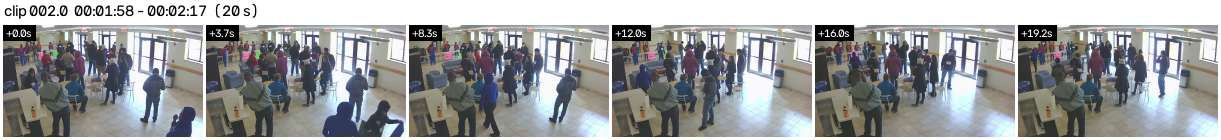

**Summary:** A person wearing a blue hoodie walks towards the center of the room, while another individual in a black jacket and jeans moves slightly to the right. The group remains mostly stationary, with some individuals adjusting their positions.  
**Actions:** person in a blue hoodie walks towards the center; person in a black jacket and jeans moves slightly to the right  
**People** (max 15 at once): man in a green jacket standing near the counter; woman in a red jacket standing near the counter; man in a black jacket with a backpack standing near the counter; woman in a blue jacket sitting at a table; man in a gray jacket standing near the counter; woman in a black coat standing near the counter; man in a black jacket and jeans moving slightly to the right; person in a blue hoodie walking towards the center  
**Vehicles:** — · **Objects:** counter with a bottle of orange liquid; couches and chairs arranged around tables; signs on the wall indicating exits  
**Labelled in this span (20):** `00:00` person_talks_to_person; `01:22` person_talks_to_person; `01:51` person_talks_to_person; `01:51` person_talks_to_person; `01:54` person_talks_to_person; `01:55` person_talks_to_person; `01:55` person_talks_to_person; `01:56` person_exits_scene_through_structure

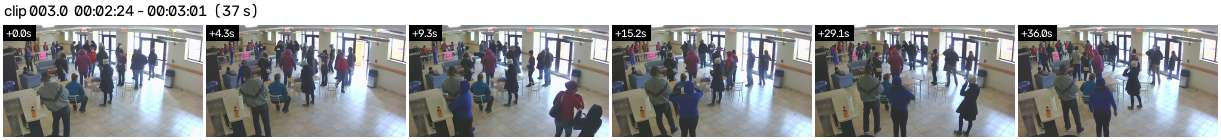

**Summary:** A group of people stands in a room, some move slightly while others remain stationary. The scene remains largely unchanged throughout the sequence.  
**Actions:** person in blue jacket moves slightly; person in red jacket walks towards the door; person in black coat adjusts their hat; person in white coat moves closer to the door  
**People** (max 18 at once): man in gray jacket with a backpack; woman in blue jacket; woman in red jacket; woman in black coat; man in white coat; woman in black coat with a hat  
**Vehicles:** — · **Objects:** signs on the wall; couches; tables; trash can; bottle on the table  
**Labelled in this span (20):** `00:00` person_talks_to_person; `01:55` person_talks_to_person; `02:15` person_talks_to_person; `02:15` person_talks_to_person; `02:19` hand_interacts_with_person; `02:19` person_texts_on_phone; `02:24` person_opens_facility_door; `02:24` person_exits_scene_through_structure

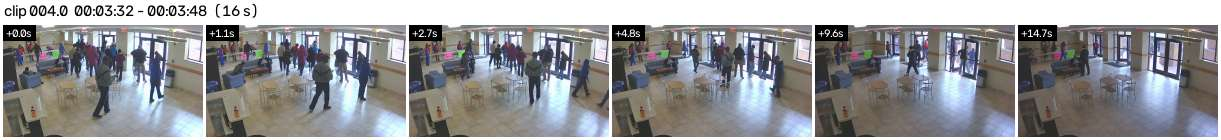

**Summary:** A group of people are entering and exiting a building through a double door. The scene remains relatively unchanged throughout the sequence.  
**Actions:** People walk into the building through the double doors.; More individuals exit the building through the same doors.  
**People** (max 10 at once): Man in a gray jacket with a backpack; Woman in a blue jacket; Man in a black jacket; Person in a red jacket; Person in a pink jacket; Person in a blue jacket; Person in a black jacket; Person in a red jacket; Person in a blue jacket; Person in a black jacket  
**Vehicles:** — · **Objects:** Double doors; Sofa; Coffee tables; Chairs; Trash bin; Signs above the doors  
**Labelled in this span (34):** `00:00` person_talks_to_person; `03:03` person_texts_on_phone; `03:05` person_texts_on_phone; `03:26` person_talks_to_person; `03:30` person_opens_facility_door; `03:30` person_exits_scene_through_structure; `03:31` person_exits_scene_through_structure; `03:31` person_exits_scene_through_structure

In [13]:
N_CLIPS = 8          # clips shown (in time order); set CLIP_IDS to pick, e.g. ["002.0", "005.1"]
CLIP_IDS = None
cap_dir = D_ / "captions"
clips_ = [json.loads(l) for l in open(cap_dir / "clip_captions.jsonl")] if (cap_dir / "clip_captions.jsonl").exists() else []
frames_ = [json.loads(l) for l in open(cap_dir / "frame_captions.jsonl")] if (cap_dir / "frame_captions.jsonl").exists() else []
if not clips_ and not frames_:
    print("no captions for this video (phase vlm_clips / vlm_frames didn't run, or failed: see error_vlm_*.json)")
else:
    sv = json.loads((D_ / "summary_vlm.json").read_text()) if (D_ / "summary_vlm.json").exists() else {}
    display(Markdown(f"**{len(clips_)} clip captions, {len(frames_)} frame captions** · model `{sv.get('vlm_model', '?')}` · "
                     f"frames from `{sv.get('vlm_source', '?')}` · unparsed answers: {sv.get('vlm_parse_failed', '?')}"))


def _lst(x):
    return "; ".join(v if isinstance(v, str) else ", ".join(f"{a}" for a in v.values()) if isinstance(v, dict) else str(v)
                     for v in x) if x else "—"


shown = [c for c in clips_ if CLIP_IDS is None or c["clip_id"] in CLIP_IDS][:N_CLIPS]
for c in shown:
    tiles = []
    for im_rel, t in zip(c["images"], c["frame_times_s"]):
        img = cv2.imread(str(D_ / im_rel))
        if img is not None:
            tiles.append(viz.label(viz.thumb(img, 200), f"+{t - c['start_s']:.1f}s", scale=0.38))
    if tiles:
        strip = viz.grid(tiles, cols=6, pad=3)
        show_img(np.vstack([viz.header(f"clip {c['clip_id']}  {c['start_hms'][:8]} - {c['end_hms'][:8]}"
                                       f"  ({c['end_s'] - c['start_s']:.0f} s)", strip.shape[1]), strip]), quality=60)
    lines = [f"**Summary:** {c['summary'] or '—'}", f"**Actions:** {_lst(c['actions'])}",
             f"**People** (max {c['people_count_max'] if c['people_count_max'] is not None else '?'} at once): {_lst(c['people'])}",
             f"**Vehicles:** {_lst(c['vehicles'])} · **Objects:** {_lst(c['objects'])}"]
    if c["notable"]:
        lines.append(f"**Notable:** {c['notable']}")
    if c["uncertain"]:
        lines.append(f"*Unclear to the model:* {c['uncertain']}")
    if not c["parse_ok"]:
        lines.append("⚠️ *answer was not valid JSON; raw text shown as the summary*")
    if gt is not None:
        g_ = gt[(gt.start_s < c["end_s"]) & (gt.end_s > c["start_s"])]
        lines.append(f"**Labelled in this span ({len(g_)}):** " +
                     ("; ".join(f"`{format_hms(x.start_s)[3:8]}` {x.label}" for x in g_.head(8).itertuples()) or "nothing"))
    display(Markdown("  \n".join(lines)))
if len(clips_) > len(shown):
    print(f"showing {len(shown)} of {len(clips_)} clips (N_CLIPS / CLIP_IDS above)")

In [14]:
N_FRAMES = 12        # first frame captions shown, numbered; the table below has the text
if frames_:
    fr_ = frames_[:N_FRAMES]
    tiles = []
    for k, f in enumerate(fr_, 1):
        img = cv2.imread(str(D_ / f["image"]))
        if img is not None:
            tiles.append(viz.label(viz.thumb(img, 220), f"#{k} {f['timestamp_hms'][3:10]}", scale=0.38))
    if tiles:
        show_img(viz.grid(tiles, cols=6, pad=3), quality=60)
    display(pd.DataFrame([{"#": k, "time": f["timestamp_hms"][3:10], "caption": f["caption"],
                           "people": f["people_count"], "vehicles": len(f["vehicles"]), "notable": f["notable"],
                           "detector saw": ", ".join(f"{n} {c}" for c, n in (f.get("detector_objects") or {}).items()),
                           "parsed": f["parse_ok"]} for k, f in enumerate(fr_, 1)]).set_index("#"))
    print("'detector saw' = YOLO-World track classes at that moment (stage 3), not shown to the VLM: "
          "an independent check on its people / vehicle counts")

## 6. Captions across all videos
- **unparsed**: answers that weren't valid JSON (kept as plain text, still searchable). Should be ~0.
- **s per clip / s per frame**: measured speed of the VLM. **est. VLM min per video-hour** = what captioning a
  whole hour of this kind of video costs at that speed (the supervisor's "hours indexed per GPU-hour").
- **complete**: every clip and frame of the video captioned (False = the run was stopped part-way).

Then three checks of caption quality (code: `caption_eval.py`): the **detector cross-check** and the comparison with
the **ground-truth labels** are automatic; the **hand check** is about 6 minutes per person for 5 people.

In [15]:
if not has("vlm_clips"):
    print("no captions yet: run phases vlm_clips / vlm_frames in pipeline.ipynb")
else:
    V = ok.dropna(subset=["vlm_clips"])
    g = V.groupby("dataset")
    t = pd.DataFrame({
        "videos": g.size(), "clips": g.vlm_clips.sum(), "clips total": g.vlm_clips_total.sum(),
        "frames": g.vlm_frames.sum(), "frames total": g.vlm_frames_total.sum(),
        "unparsed": g.vlm_parse_failed.sum(),
        "s per clip": g.vlm_s_per_clip.mean(), "s per frame": g.vlm_s_per_frame.mean(),
        "est. VLM min per video-hour": g.apply(lambda x: (x.vlm_min_per_video_hour * x.duration_s).sum() / x.duration_s.sum()),
        "videos complete": g.vlm_complete.apply(lambda x: int(x.astype(str).eq("True").sum())),
    })
    if "vlm_peak_vram_gb" in V:
        t["peak VRAM GB"] = g.vlm_peak_vram_gb.max()
    display(t.round(2))
    cols = ["dataset", "video_id", "minutes", "vlm_source", "vlm_clips", "vlm_frames", "vlm_parse_failed",
            "vlm_s_per_clip", "vlm_s_per_frame", "vlm_min_per_video_hour", "vlm_complete"]
    display(V[[c for c in cols if c in V]].sort_values(["dataset", "video_id"]).reset_index(drop=True).round(2))

,videos,clips,clips total,frames,frames total,unparsed,s per clip,s per frame,est. VLM min per video-hour,videos complete,peak VRAM GB
dataset,,,,,,,,,,,
meva,12,64,64,220,1631,2,10.89,3.77,25.99,2,19.75
uca,26,103,103,0,1042,1,8.76,NaN,14.39,0,17.37


,dataset,video_id,minutes,vlm_source,vlm_clips,vlm_frames,vlm_parse_failed,vlm_s_per_clip,vlm_s_per_frame,vlm_min_per_video_hour,vlm_complete
0,meva,2018-03-13.15-50-00.15-55-00.school.G328.r13,5.00,index,8,82,0,9.36,3.55,73.24,True
1,meva,2018-03-13.15-50-00.15-55-00.school.G421.r13,5.00,index,8,0,1,16.45,NaN,26.32,False
2,meva,2018-03-13.15-50-02.15-55-02.school.G424.r13,5.00,index,8,0,0,8.16,NaN,13.04,False
3,meva,2018-03-13.15-50-03.15-55-03.school.G336.r13,5.00,index,6,138,0,10.03,3.98,121.77,True
4,meva,2018-03-13.15-55-00.16-00-00.school.G328.r13,5.00,index,6,0,1,11.33,NaN,13.60,False
5,meva,2018-03-13.15-55-00.16-00-00.school.G421.r13,5.00,index,6,0,0,17.95,NaN,21.54,False
6,meva,2018-03-13.15-55-02.16-00-02.school.G424.r13,5.00,index,4,0,0,7.18,NaN,5.74,False
7,meva,2018-03-13.15-55-03.16-00-03.school.G336.r13,5.00,index,4,0,0,10.10,NaN,8.07,False
8,meva,2018-03-13.16-05-00.16-10-00.school.G328.r13,5.00,index,3,0,0,7.69,NaN,4.61,False
9,meva,2018-03-13.16-05-00.16-10-00.school.G421.r13,5.00,index,1,0,0,11.17,NaN,2.23,False


### What the VLM flagged as unusual
Every clip whose `notable` field isn't empty, with the labelled moments of the same span. Good examples for the
report: true alarms (a fight, a fall) and false ones (normal scenes the model over-read).

In [16]:
rows = []
for _, r in ok.iterrows():
    p = vdir(r) / "captions" / "clip_captions.jsonl"
    if not p.exists():
        continue
    g_ = read_csv(vdir(r) / "gt.csv")
    for c in map(json.loads, open(p)):
        if c.get("notable"):
            lab = "" if g_ is None else "; ".join(g_[(g_.start_s < c["end_s"]) & (g_.end_s > c["start_s"])].label.astype(str).head(3))
            rows.append({"dataset": r.dataset, "video_id": r.video_id, "clip": c["clip_id"],
                         "time": f"{c['start_hms'][3:8]}-{c['end_hms'][3:8]}", "notable": c["notable"], "labelled": lab})
if rows:
    display(pd.DataFrame(rows).head(40))
    print(f"{len(rows)} clips flagged" + (" (first 40 shown)" if len(rows) > 40 else ""))
else:
    print("no clip captions with a 'notable' field (or no captions yet)")

,dataset,video_id,clip,time,notable,labelled
0,uca,Explosion042_x264,000.0,00:01-00:32,"The bright overexposure and subsequent dark, s...",Many people are standing at an intersection; A...
1,uca,Explosion050_x264,000.0,00:00-00:09,dust cloud,"There were many cars parked on the road, and a..."
2,uca,Fighting045_x264,000.0,00:24-00:56,Physical altercation between two individuals,A man walks out and a man fights with two men;...
3,uca,Fighting049_x264,000.0,00:04-00:38,Physical altercation,"A man punched and kicked a sitting man, and th..."


4 clips flagged


### Detector cross-check (automatic, every clip)
What each clip caption mentions (people, vehicles, two-wheelers, bags, boxes, carts, dogs) against what YOLO-World
tracked for at least 1 s in the same seconds. **Likely hallucination** = mentioned but never tracked; **likely miss** =
tracked but not mentioned; people count = the caption's maximum vs the most people tracked in one frame. A cheap
screen, not ground truth: it covers only the detector's classes (no actions, no colours) and the detector errs
too (small or far objects, tracker ID switches in crowds). The hand check below says how far to trust it.

In [17]:
cc = ce.detector_crosscheck(OUT_ROOT)
if cc.empty:
    print("no clip captions or no stage-3 tracks yet (phases gpu and vlm_clips in pipeline.ipynb)")
else:
    per_ds, per_cat = ce.crosscheck_summary(cc)
    display(per_ds)
    display(Markdown("**Per category**: how often a caption mention is backed by a detection, and a detection is mentioned"))
    display(per_cat)
    fl = cc[cc.likely_hallucination != ""]
    display(Markdown(f"**Clips whose caption names something the detector never tracked** ({len(fl)}, first 15):"))
    display(fl[["dataset", "video_id", "clip_id", "time", "likely_hallucination", "people_vlm", "people_detector",
                "summary"]].head(15).reset_index(drop=True))

,clips,clips with a likely hallucination %,clips with a likely miss %,people count within ±25% of detector %,mean |people VLM - detector|
dataset,,,,,
meva,64,15.6,43.8,59.7,3.0
uca,103,26.2,28.2,85.3,1.5


**Per category**: how often a caption mention is backed by a detection, and a detection is mentioned

,clips mentioning,clips with a detection,mentions backed by detector %,detections mentioned %
category,,,,
person,153,149,94.8,97.3
vehicle,70,96,94.3,68.8
two-wheeler,6,4,16.7,25.0
bag,25,16,32.0,50.0
box,1,11,0.0,0.0
cart,3,2,0.0,0.0
dog,2,4,50.0,25.0


**Clips whose caption names something the detector never tracked** (37, first 15):

,dataset,video_id,clip_id,time,likely_hallucination,people_vlm,people_detector,summary
0,meva,2018-03-13.15-50-00.15-55-00.school.G421.r13,000.0,00:01-00:28,bag,12.0,16,A group of people wearing red vests are seen m...
1,meva,2018-03-13.15-50-00.15-55-00.school.G421.r13,002.0,01:52-01:59,bag,8.0,8,A man in a black jacket walks towards the exit...
2,meva,2018-03-13.15-50-00.15-55-00.school.G421.r13,003.0,02:04-02:19,bag,8.0,10,"A man in a black jacket walks into the room, t..."
3,meva,2018-03-13.15-50-00.15-55-00.school.G421.r13,005.0,03:18-04:03,bag,NaN,24,"{ ""summary"": ""A group of people are gathered i..."
4,meva,2018-03-13.15-50-00.15-55-00.school.G421.r13,007.0,04:46-05:00,bag,18.0,17,"A person in a blue jacket walks into the room,..."
5,meva,2018-03-13.15-55-00.16-00-00.school.G421.r13,001.0,01:38-01:54,bag,20.0,23,A person in a red jacket exits through the doo...
6,meva,2018-03-13.15-55-00.16-00-00.school.G421.r13,004.0,03:32-03:48,bag,10.0,18,A group of people are entering and exiting a b...
7,meva,2018-03-13.16-05-00.16-10-00.school.G328.r13,002.0,03:27-04:08,bag,8.0,7,"The scene remains largely unchanged, with a fe..."
8,meva,2018-03-13.16-05-00.16-10-00.school.G421.r13,000.0,03:51-04:26,bag,3.0,3,A group of three individuals enter the buildin...
9,meva,2018-03-13.16-05-02.16-10-02.school.G424.r13,004.1,04:05-04:44,bag,10.0,18,A person in a red jacket walks across the park...


### Captions vs the ground-truth labels (automatic)
Each label (UCA: a human sentence; MEVA: an activity name such as "person opens facility door") is paired with the
clip caption covering the same seconds, and the two texts are compared with a sentence-embedding model (`bge-small`,
downloaded once, ~130 MB; TF-IDF if it can't be downloaded). A similarity alone means little, so it is compared with
the same label against captions of *other* videos. **top-1 / top-5** = the most similar captions of the whole dataset
include a clip covering the label: caption-only search on the labels. Labels not covered by any clip were lost at the
gating stage and are counted separately. UCA's sentences are short and about one event, so a correct but more detailed
caption still scores lower: read this next to the hand check.

In [18]:
pairs, lab_summary = ce.label_similarity(OUT_ROOT)
if pairs.empty:
    print("no captions or no ground truth yet")
else:
    display(Markdown(f"Text model: `{lab_summary.attrs.get('embedder')}`"))
    display(lab_summary.T)
    u = pairs[pairs.covered_by_a_clip & (pairs.dataset == "uca")].sort_values("sim_matched", ascending=False)
    if len(u):
        cols = ["video_id", "label_time", "label", "caption", "sim_matched", "sim_other_videos", "top1"]
        display(Markdown("**UCA: most similar pairs** (label vs the caption of its clip)"))
        display(u[cols].head(5).reset_index(drop=True))
        display(Markdown("**UCA: least similar pairs**"))
        display(u[cols].tail(5).reset_index(drop=True))

/mnt/5T_storage/clipsExtraction/tools/awsenv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 199/199 [00:00<00:00, 6096.28it/s]


Text model: `BAAI/bge-small-en-v1.5 (sentence model)`

dataset,meva,uca
labels,680,194
covered by a clip %,72.35,88.66
"similarity, matching caption",0.58,0.56
"similarity, other videos' captions",0.55,0.47
gap,0.03,0.09
matching caption beats other videos' average %,64.02,83.14
top-1 is a covering clip %,3.05,15.12
top-5 has a covering clip %,17.28,35.47


**UCA: most similar pairs** (label vs the caption of its clip)

,video_id,label_time,label,caption,sim_matched,sim_other_videos,top1
0,Shooting052_x264,86.7-93.5,The red car left the parking lot,"A red car drives out of the parking lot, follo...",0.86,0.49,True
1,Normal_Videos673_x264,6.2-16.9,Two cars passed by the road next to the parkin...,A white car drives into the parking lot and pa...,0.81,0.59,True
2,Normal_Videos673_x264,62.9-71.8,Screen transition: A woman passes by the door ...,"A person walks into a store, interacts at the ...",0.79,0.54,True
3,Stealing109_x264,71.0-79.2,A car is driving behind a parked silver car,A silver SUV is parked in front of a building ...,0.79,0.52,False
4,RoadAccidents147_x264,58.8-73.7,Two cars passed by,"A white van drives through an intersection, fo...",0.77,0.59,False


**UCA: least similar pairs**

,video_id,label_time,label,caption,sim_matched,sim_other_videos,top1
0,Shoplifting052_x264,52.8-63.7,This man took off another pair of glasses from...,A man in a yellow and green jacket stands near...,0.38,0.41,False
1,Abuse045_x264,0.0-12.0,The woman lying on the sofa kicked the old man...,"A person walks into the room carrying a child,...",0.38,0.37,False
2,Burglary090_x264,9.2-14.4,A red car smashed into the glass door of the shop,The scene remains static throughout the sequen...,0.36,0.47,False
3,Burglary090_x264,14.3-16.5,2 men in black broke into the shop.,The scene remains static throughout the sequen...,0.32,0.45,False
4,Normal_Videos660_x264,29.8-33.6,"The last man put in the coin and walked back, ...","A woman in a red jacket boards the bus, follow...",0.30,0.44,False


### Hand check: hallucination and miss rate (about 6 minutes per person)
30 random clip captions split over 5 people: `outputs/batch/clip_review/review_1.html` … `review_5.html` show each
clip's frames next to its caption; fill in the matching `review_<k>.csv` (Excel or Google Sheets, save as CSV):
- **hallucinations (count)**: things the caption names that are not in the frames (a person, colour, object, action);
- **misses (count)**: clearly visible people / vehicles / objects / actions it doesn't mention;
- **people count ok (y/n)**: is the maximum number of people about right? Write 0 when there are none.

The sheets are made once and never overwritten, so filled-in answers are safe; re-run this cell for the results.
To make new sheets (e.g. after a new run), delete the `clip_review` folder first.

In [19]:
REVIEW_CLIPS, REVIEWERS = 30, 5
folder = ce.make_review_sheets(OUT_ROOT, n=REVIEW_CLIPS, reviewers=REVIEWERS)
if folder is None:
    print("no clip captions yet")
else:
    print(f"sheets in {folder}: review_1 … review_{REVIEWERS} (.html to look at, .csv to fill in)")
    res, done = ce.review_results(OUT_ROOT, cc if len(cc) else None)
    if res.empty:
        print("no answers yet: fill in the CSVs, save, and re-run this cell")
    else:
        display(res.T)
        print("'detector check agrees' = how often the automatic cross-check above said the same as the reviewers")

sheets in outputs/batch/clip_review: review_1 … review_5 (.html to look at, .csv to fill in)
no answers yet: fill in the CSVs, save, and re-run this cell


## 7. Run times: how fast is indexing?
Supervisor's question: hours of video indexed per GPU-hour. Stages 1-2 run on the CPU, stages 3-4 and the captions (stage 5) on the GPU.
(Videos loaded from the stage-1 cache show a near-zero scan time; `FRESH_RUN = True` with `KEEP_DECODE_CACHE = False`
in `pipeline.ipynb` gives honest numbers.) Caption times are those of the last run that captioned each level.

In [20]:
cols = [c for c in ["scan_s", "keyframes_s", "deep_gate_s", "cpu_s", "stage3_s", "stage4_s", "gpu_s",
                    "vlm_clips_s", "vlm_frames_s", "vlm_s"] if c in ok]
t = ok.groupby("dataset")[cols + ["duration_s"]].sum()
for c in cols:
    t[f"{c} per video-hour (min)"] = t[c] / 60 / (t.duration_s / 3600)
t["video hours"] = t.duration_s / 3600
display(t.drop(columns="duration_s").round(2).T)
if "from_cache" in ok and ok.from_cache.astype(str).eq("True").any():
    print(f"note: {int(ok.from_cache.astype(str).eq('True').sum())} video(s) had their stage-1 scan loaded from cache")

dataset,meva,uca
scan_s,243.36,150.41
keyframes_s,20.93,10.64
cpu_s,264.28,161.05
stage3_s,248.35,204.50
stage4_s,47.99,12.16
gpu_s,296.34,216.66
vlm_clips_s,719.56,867.55
vlm_frames_s,840.43,0.00
vlm_s,1608.02,875.56
scan_s per video-hour (min),4.05,2.50


## 8. Search: does typing a sentence find the right clip?
Reads `outputs/batch/search/` (run **`search.ipynb`** first). Every test query was run through every method:
`captions` (caption text), `siglip_selected` (SigLIP on the frames the pipeline picked), `hybrid` (both merged), and
two baselines that skip the pipeline: `siglip_1fps` and `clip_1fps` (1 frame per second of every video).
- **R@K IoU0.3**: a returned 10-s moment overlaps an answer by IoU ≥ 0.3 within the top K (strict: the exact moment).
- **R@K lenient**: a returned clip overlaps an answer at all within the top K (the operator lands in the right place).
- **reachable %**: answers that overlap any clip. The pipeline's methods can't beat this; the baselines can.
- **corpus** = search all videos of the dataset; **video** = only the query's own video (UCA only).

In [21]:
SR = se.load_outputs(OUT_ROOT)
if SR["metrics"] is None:
    print("no search results yet: run search.ipynb")
else:
    run = SR["run"]
    display(Markdown(f"{run.get('queries')} queries · {run.get('clips')} clips · {run.get('selected_frames')} selected "
                     f"frames · {run.get('baseline_frames')} baseline frames · text model `{run.get('text_embedder')}` · "
                     f"run {run.get('time')}"))
    main = ["queries", "reachable %", "R@1 IoU0.3", "R@5 IoU0.3", "R@10 IoU0.3", "R@5 IoU0.5",
            "R@1 lenient", "R@5 lenient", "R@10 lenient", "R@5 lenient | reachable", "MRR IoU0.3"]
    for (d, setting), g in SR["metrics"].groupby(["dataset", "setting"], sort=False):
        display(Markdown(f"**{d}, {setting}**"))
        display(g.set_index("method")[[c for c in main if c in g]])

218 queries · 167 clips · 2673 selected frames · 7239 baseline frames · text model `BAAI/bge-small-en-v1.5 (sentence model)` · run 2026-11-26 11:47:57

**meva, corpus**

,queries,reachable %,R@1 IoU0.3,R@5 IoU0.3,R@10 IoU0.3,R@5 IoU0.5,R@1 lenient,R@5 lenient,R@10 lenient,R@5 lenient | reachable,MRR IoU0.3
method,,,,,,,,,,,
captions,24,95.83,8.33,25.00,29.17,8.33,33.33,62.50,75.00,65.22,0.12
siglip_selected,24,95.83,8.33,16.67,33.33,12.50,16.67,50.00,75.00,52.17,0.13
hybrid,24,95.83,4.17,25.00,33.33,8.33,25.00,79.17,87.50,82.61,0.13
siglip_1fps,24,95.83,4.17,12.50,29.17,8.33,16.67,33.33,50.00,34.78,0.09
clip_1fps,24,95.83,4.17,12.50,20.83,4.17,8.33,29.17,45.83,30.43,0.07


**uca, corpus**

,queries,reachable %,R@1 IoU0.3,R@5 IoU0.3,R@10 IoU0.3,R@5 IoU0.5,R@1 lenient,R@5 lenient,R@10 lenient,R@5 lenient | reachable,MRR IoU0.3
method,,,,,,,,,,,
captions,194,88.66,6.70,14.43,19.59,7.73,10.82,32.47,46.39,36.63,0.11
siglip_selected,194,88.66,6.19,17.01,26.29,11.34,13.40,32.99,48.97,37.21,0.12
hybrid,194,88.66,7.73,19.59,22.68,12.37,13.92,42.27,52.06,47.67,0.12
siglip_1fps,194,88.66,5.67,19.07,30.93,13.40,9.28,27.32,44.33,30.23,0.12
clip_1fps,194,88.66,5.15,18.04,26.29,10.82,6.70,22.16,36.60,20.93,0.11


**uca, video**

,queries,reachable %,R@1 IoU0.3,R@5 IoU0.3,R@10 IoU0.3,R@5 IoU0.5,R@1 lenient,R@5 lenient,R@10 lenient,R@5 lenient | reachable,MRR IoU0.3
method,,,,,,,,,,,
captions,194,88.66,12.37,35.05,38.66,20.10,32.99,82.99,88.66,93.60,0.21
siglip_selected,194,88.66,17.53,40.72,52.06,23.71,39.69,78.35,88.14,86.63,0.27
hybrid,194,88.66,14.95,35.05,38.66,19.07,37.11,82.47,88.66,93.02,0.23
siglip_1fps,194,88.66,17.01,44.85,62.37,25.77,27.32,66.49,85.57,69.19,0.29
clip_1fps,194,88.66,15.46,47.94,61.86,28.35,21.65,69.07,86.08,70.93,0.29


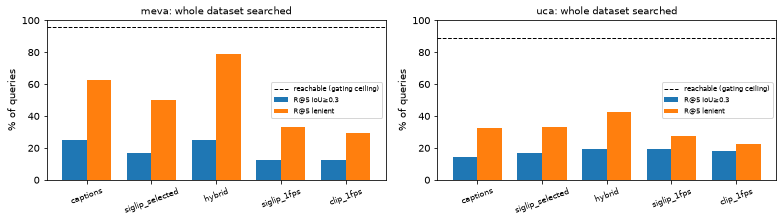

In [22]:
if SR["metrics"] is not None:
    m = SR["metrics"][SR["metrics"].setting == "corpus"]
    groups = list(m.groupby("dataset", sort=False))
    fig, axes = plt.subplots(1, len(groups), figsize=(5.5 * len(groups), 3.2), squeeze=False)
    for ax, (d, g) in zip(axes[0], groups):
        x = np.arange(len(g))
        for j, (col, lab) in enumerate([("R@5 IoU0.3", "R@5 IoU≥0.3"), ("R@5 lenient", "R@5 lenient")]):
            ax.bar(x + (j - 0.5) * 0.38, g[col], 0.38, label=lab)
        ax.axhline(g["reachable %"].iloc[0], color="k", ls="--", lw=1, label="reachable (gating ceiling)")
        ax.set_xticks(x, g.method, rotation=20, fontsize=8)
        ax.set_ylim(0, 100); ax.set_ylabel("% of queries"); ax.set_title(f"{d}: whole dataset searched", fontsize=10)
        ax.legend(fontsize=7)
    fig.tight_layout()
    show_fig(fig)

### Where are the misses: gating or search?
For the `hybrid` method (corpus setting): **gating miss** = no clip overlaps the answer (stages 1-2 dropped it),
**search miss** = a clip covers it but isn't in the top 5, **found** = in the top 5 (lenient).

In [23]:
if SR["per_query"] is not None:
    pq = SR["per_query"]
    h = pq[(pq.method == "hybrid") & (pq.setting == "corpus")].copy()
    h["outcome"] = np.where(~h.reachable.astype(bool), "gating miss",
                            np.where(h.clip_first_hit_lenient <= 5, "found (top 5)", "search miss"))
    display((h.groupby("dataset").outcome.value_counts(normalize=True).unstack(fill_value=0) * 100).round(1))

outcome,found (top 5),gating miss,search miss
dataset,,,
meva,79.2,4.2,16.7
uca,42.3,11.3,46.4


### MEVA: recall per activity
One query per activity type (e.g. *"a person opens a car door"*), answered by every labelled instance. R@5 lenient
per method, with the number of instances. Activities with few instances say little.

In [24]:
if SR["per_query"] is not None:
    mv = pq[(pq.dataset == "meva") & (pq.setting == "corpus")]
    if len(mv):
        t = mv.assign(hit=(mv.clip_first_hit_lenient <= 5) * 100).pivot_table(
            index=["label", "text"], columns="method", values="hit", aggfunc="first")
        t = t[[c for c in se.METHODS if c in t]]
        q = SR["queries"].set_index("label").n_gt
        t.insert(0, "instances", [q.get(l, 0) for l, _ in t.index])
        display(t.sort_values("instances", ascending=False))
    else:
        print("no MEVA queries")

,method,instances,captions,siglip_selected,hybrid,siglip_1fps,clip_1fps
label,text,,,,,,
person_talks_to_person,two people talking to each other,149,100,100,100,100,100
person_exits_scene_through_structure,a person leaves through a door,69,100,100,100,100,100
person_picks_up_object,a person picks up an object,69,100,100,100,0,0
person_texts_on_phone,a person texting on a phone,63,100,100,100,100,0
person_puts_down_object,a person puts an object down,46,100,0,100,0,0
person_transfers_object,a person hands an object to another person,45,0,100,100,100,100
hand_interacts_with_person,a person touches another person with their hand,43,100,100,100,100,100
person_opens_facility_door,a person opens a door,37,100,100,100,100,0
vehicle_turns_left,a car turning left,24,100,0,100,0,100


### Examples: what did it return?
For a few queries (`hybrid`, corpus): the answer, then the top 5 results, each the frame at its best moment.
**Green** = overlaps an answer, **red** = doesn't. First some found, then some missed although a clip covered the answer.

**found (top 5)**

`meva_014` *"a person sits down"* → answer: 2018-03-13.15-50-00.15-55-00.school.G421.r13 00:02:29.130-00:02:29.830; 2018-03-13.15-50-00.15-55-00.school.G421.r13 00:02:35.630-00:02:36.230; 2018-03-13.15-50-00.15-55-00.school.G421.r13 00:03:16.530-00:03:18.570 (+3 more)

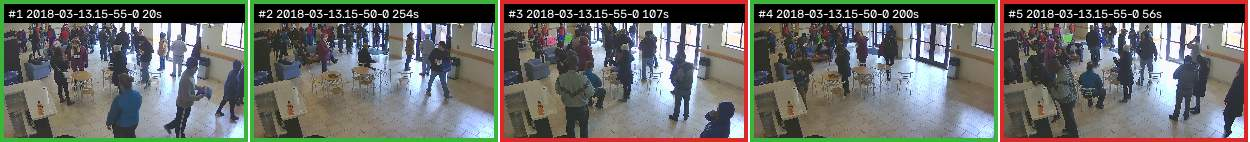

`meva_004` *"a person closes a car door"* → answer: 2018-03-13.15-50-00.15-55-00.school.G328.r13 00:00:00.000-00:00:02.530; 2018-03-13.15-50-00.15-55-00.school.G328.r13 00:02:55.130-00:02:57.000; 2018-03-13.15-50-00.15-55-00.school.G328.r13 00:02:59.900-00:03:02.600 (+6 more)

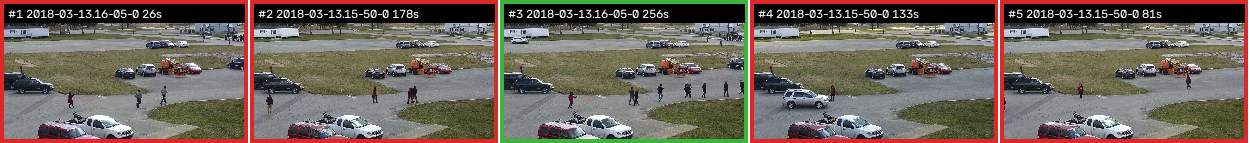

`meva_012` *"a person picks up an object"* → answer: 2018-03-13.15-50-00.15-55-00.school.G421.r13 00:00:02.330-00:00:02.830; 2018-03-13.15-50-00.15-55-00.school.G421.r13 00:00:03.700-00:00:04.170; 2018-03-13.15-50-00.15-55-00.school.G421.r13 00:00:03.800-00:00:04.300 (+66 more)

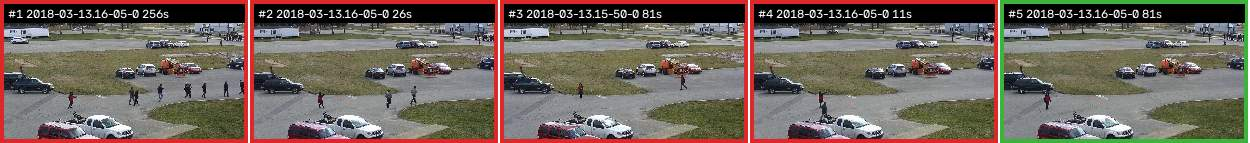

`uca_064` *" Several people dispersed, passers-by kept passing by"* → answer: Fighting045_x264 00:00:21.200-00:00:26.900

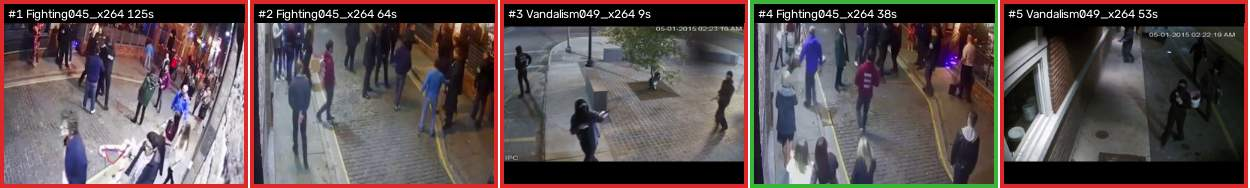

`uca_008` *"The woman walked to the side of the sofa and pushed the old man’s head, then walked out the door."* → answer: Abuse045_x264 00:01:18.300-00:01:27.300

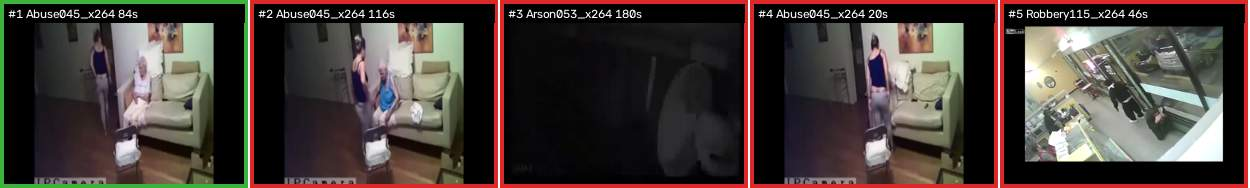

`uca_135` *"This man watches the shelves again"* → answer: Shoplifting052_x264 00:01:34.000-00:02:08.900

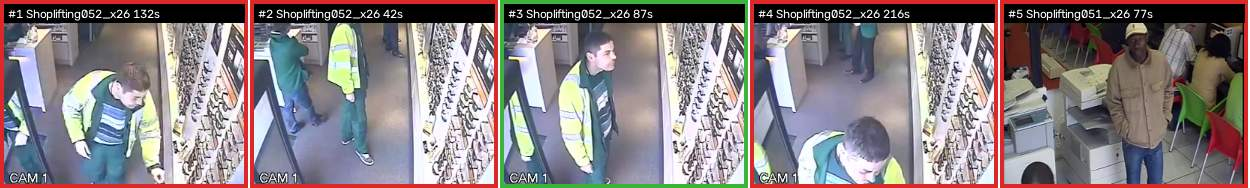

**search miss**

`meva_016` *"a person talking on a phone"* → answer: 2018-03-13.15-50-00.15-55-00.school.G421.r13 00:03:51.630-00:03:57.170; 2018-03-13.15-55-03.16-00-03.school.G336.r13 00:02:21.770-00:02:25.370

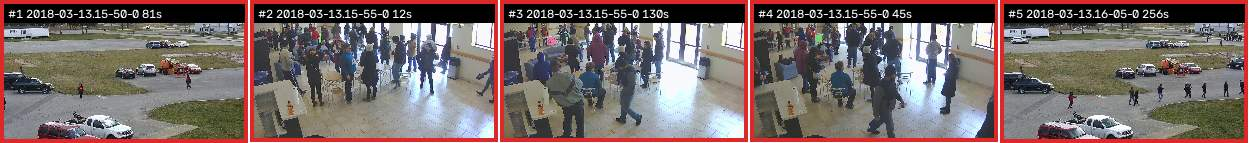

`meva_020` *"a car reversing"* → answer: 2018-03-13.15-50-00.15-55-00.school.G328.r13 00:00:01.800-00:00:12.800; 2018-03-13.15-50-00.15-55-00.school.G328.r13 00:01:09.600-00:01:25.070; 2018-03-13.15-50-00.15-55-00.school.G328.r13 00:03:07.370-00:03:08.370 (+7 more)

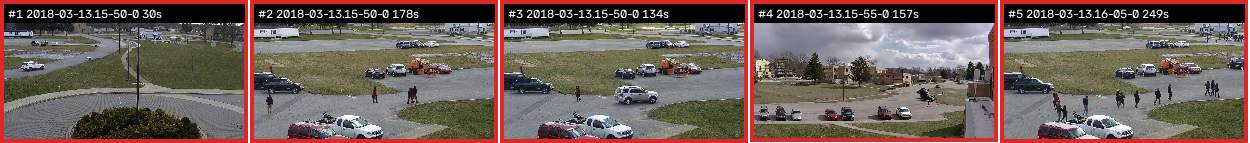

`meva_011` *"a person opens a car door"* → answer: 2018-03-13.15-50-00.15-55-00.school.G328.r13 00:02:53.030-00:02:55.200; 2018-03-13.15-50-00.15-55-00.school.G328.r13 00:02:57.530-00:03:00.130; 2018-03-13.15-50-02.15-55-02.school.G424.r13 00:00:01.830-00:00:04.400 (+5 more)

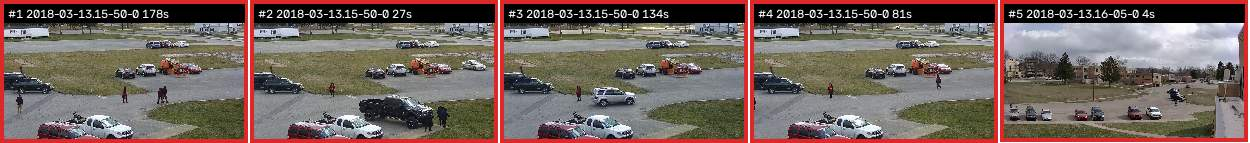

`uca_013` *"The woman is talking to the old man,"* → answer: Abuse045_x264 00:02:26.300-00:02:33.200

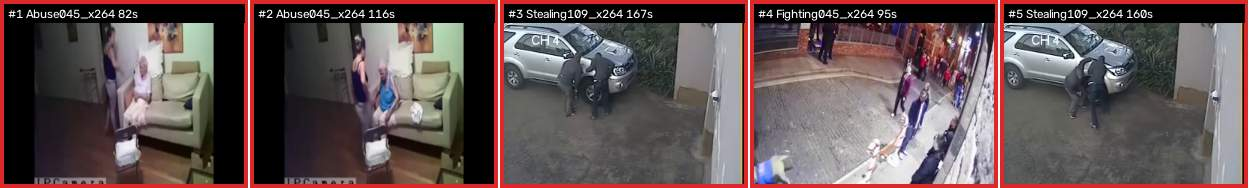

`uca_033` *"The customer returned to the store and quarreled with the owner."* → answer: Assault041_x264 00:01:30.600-00:01:40.900

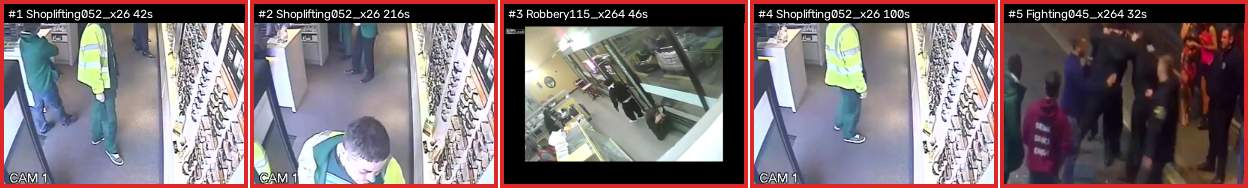

`uca_121` *"The man wearing a white hat walked into the house"* → answer: Shoplifting051_x264 00:00:35.700-00:00:46.700

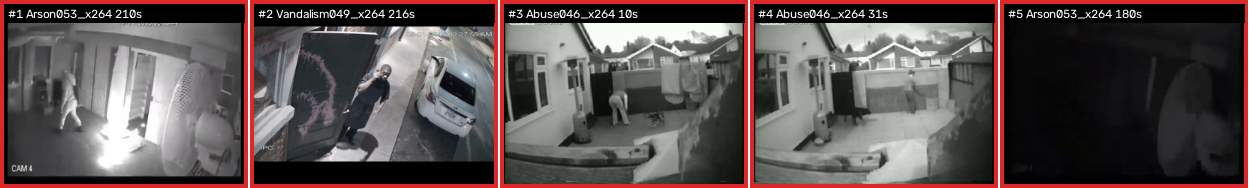

In [25]:
N_EXAMPLES = 3
if SR["results"] is not None and len(SR["results"]):
    R = SR["results"]
    Q = SR["queries"].set_index("query_id")
    for outcome in ["found (top 5)", "search miss"]:
        display(Markdown(f"**{outcome}**"))
        if not (h.outcome == outcome).any():
            print("none")
        for ds_name, g in h[h.outcome == outcome].groupby("dataset"):
            for qid in g.sample(min(N_EXAMPLES, len(g)), random_state=0).query_id:
                q = Q.loc[qid]
                ans = "; ".join(f"{v} {format_hms(a)}-{format_hms(b)}" for v, a, b in q.gt_spans[:3])
                more = f" (+{len(q.gt_spans) - 3} more)" if len(q.gt_spans) > 3 else ""
                display(Markdown(f"`{qid}` *\"{q.text}\"* → answer: {ans}{more}"))
                r = R[(R.query_id == qid) & (R.method == "hybrid") & (R.setting == "corpus")].sort_values("rank")
                img = se.result_strip(r, q.gt_spans)
                if img is not None:
                    show_img(img)

### Operator-style queries (no ground truth)
The free-text questions at the end of `search.ipynb`: the top result of each, with its caption. Judge by eye.

,query,dataset,video_id,clip_start,clip_end,summary
0,someone running,uca,Vandalism049_x264,203.2,255.80,A person wearing a dark shirt and pants walks ...
3,a fight between two people,uca,Fighting049_x264,4.8,38.60,A man in a black jacket stands up and appears ...
6,a person falls to the ground,uca,Fighting045_x264,80.6,134.80,A group of people gather around an individual ...
9,a car crash,uca,Vandalism044_x264,2.8,40.90,"A person walks between two parked cars, then a..."
12,a person carrying a bag,uca,Abuse045_x264,9.6,23.20,"A person walks into the room carrying a child,..."
15,a group of people standing together,meva,2018-03-13.15-55-00.16-00-00.school.G421.r13,144.6,181.20,"A group of people stands in a room, some move ..."
18,a person on a bicycle,uca,Fighting045_x264,80.6,134.80,A group of people gather around an individual ...
21,a car parked by the door,uca,Stealing109_x264,252.4,299.00,A silver SUV is parked near a building. A pers...
24,a person in a red shirt,uca,Shooting052_x264,111.6,138.40,A person walks past the red car in the parking...
27,someone walking at night,uca,Vandalism049_x264,147.2,156.60,"A person walks down the sidewalk, followed by ..."


*"someone running"*

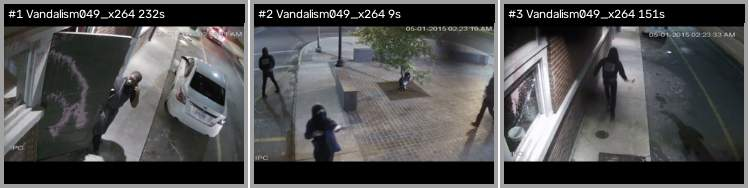

*"a fight between two people"*

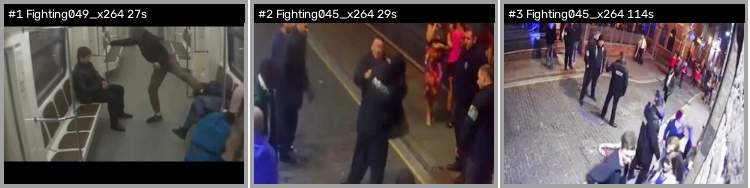

*"a person falls to the ground"*

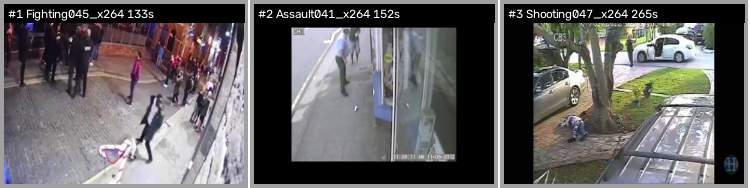

*"a car crash"*

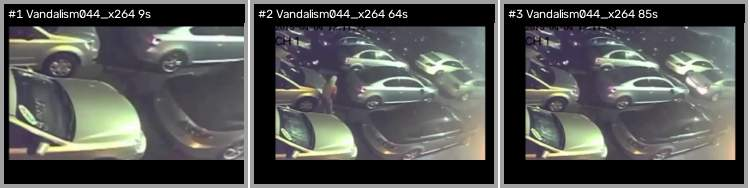

*"a person carrying a bag"*

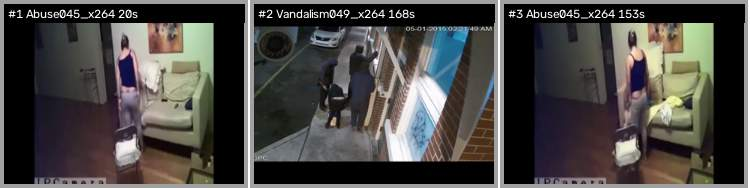

*"a group of people standing together"*

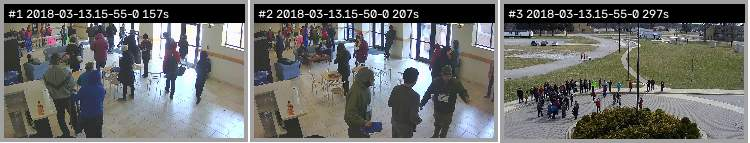

*"a person on a bicycle"*

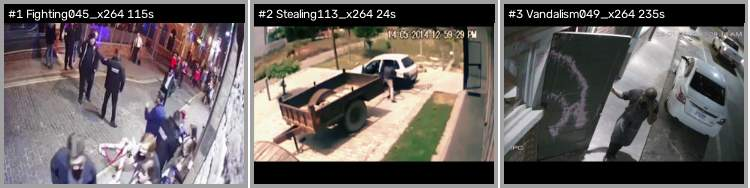

*"a car parked by the door"*

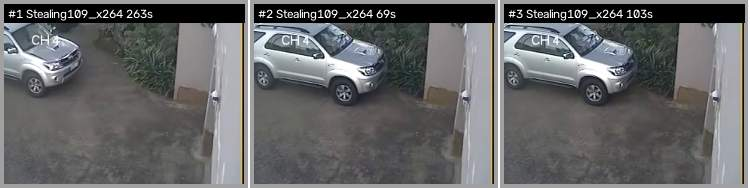

In [26]:
if SR["demo_results"] is not None:
    D = SR["demo_results"]
    top = D[D["rank"] == 1]
    display(top[["query", "dataset", "video_id", "clip_start", "clip_end", "summary"]])
    for qtext, g in list(D.groupby("query", sort=False))[:8]:
        display(Markdown(f"*\"{qtext}\"*"))
        img = se.result_strip(g.sort_values("rank"), None, n=3)
        if img is not None:
            show_img(img)

### Search speed and index size
Time for one query (encode the text, rank everything) and the size of what is searched. The baselines rank
far more vectors (1 per second of video) than the pipeline's methods (only the kept clips and frames).

In [27]:
if SR["latency"] is not None:
    lat = SR["latency"].set_index("method")
    run = SR["run"]
    size = {"captions": run.get("clips"), "hybrid": run.get("clips"), "siglip_selected": run.get("selected_frames"),
            "siglip_1fps": run.get("baseline_frames"), "clip_1fps": run.get("baseline_frames")}
    lat["vectors searched"] = [size.get(m) for m in lat.index]
    display(lat.rename(columns={"median": "median ms", "p95": "p95 ms"}))
    display(pd.Series(run.get("timings", {}), name="seconds").round(1).to_frame())

,median ms,p95 ms,vectors searched
method,,,
captions,36.6,39.7,167
siglip_selected,37.4,38.7,2673
hybrid,35.7,37.4,167
siglip_1fps,40.7,63.4,7239
clip_1fps,37.8,40.8,7239


,seconds
index_s,6.1
baselines_s,190.9
encode_queries_s,0.3
